In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

print("BYD analysis setup successful!")

BYD analysis setup successful!


In [3]:
TICKER = "BYDDY"
START_DATE = "2026-01-01"
END_DATE = "2026-10-12"

byd = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

if byd.empty:
    raise ValueError(
        "No data downloaded. Check the ticker and internet connection."
    )

if isinstance(byd.columns, pd.MultiIndex):
    byd = byd.xs(TICKER, axis=1, level="Ticker")

byd = byd.sort_index()

print("First trading date:", byd.index.min().date())
print("Last trading date:", byd.index.max().date())
print("Number of rows:", len(byd))

display(byd.head())

First trading date: 2026-01-02
Last trading date: 2026-10-09
Number of rows: 194


Price,Close,High,Low,Open,Volume
Date,,,,,
2026-01-02,12.698576,12.738383,12.579154,12.628912,2580800
2026-01-05,12.409972,12.409972,12.191031,12.400020,2430200
2026-01-06,12.549297,12.698576,12.549297,12.688624,1485500
2026-01-07,12.041754,12.280598,12.041754,12.250743,2219600
2026-01-08,12.131319,12.161175,12.011897,12.041753,808800


In [4]:
print("Columns:", byd.columns.tolist())

print("\nData types:")
print(byd.dtypes)

print("\nMissing values:")
print(byd.isna().sum())

print("\nDuplicate dates:", byd.index.duplicated().sum())

Columns: ['Close', 'High', 'Low', 'Open', 'Volume']

Data types:
Price
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Missing values:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Duplicate dates: 0


In [5]:
print("Columns:", byd.columns.tolist())

print("\nData types:")
print(byd.dtypes)

print("\nMissing values:")
print(byd.isna().sum())

print("\nDuplicate dates:", byd.index.duplicated().sum())

Columns: ['Close', 'High', 'Low', 'Open', 'Volume']

Data types:
Price
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Missing values:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Duplicate dates: 0


In [1]:
%pip install yfinance pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 6.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 16.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [yfinance]/17 [yfinance]s]

[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
# Calculate daily percentage returns
byd["Daily Return"] = byd["Close"].pct_change() * 100

# Calculate descriptive statistics
print("BYD Daily Return Statistics (%)")
print(byd["Daily Return"].describe())

print("\nBYD Closing Price Statistics ($)")
print(byd["Close"].describe())

BYD Daily Return Statistics (%)
count    193.000000
mean      -0.114604
std        2.382061
min       -6.548100
25%       -1.470592
50%       -0.401926
75%        1.221504
max        8.061897
Name: Daily Return, dtype: float64

BYD Closing Price Statistics ($)
count    194.000000
mean      11.745836
std        1.194431
min        9.270000
25%       11.015000
50%       11.781502
75%       12.653793
max       14.280923
Name: Close, dtype: float64


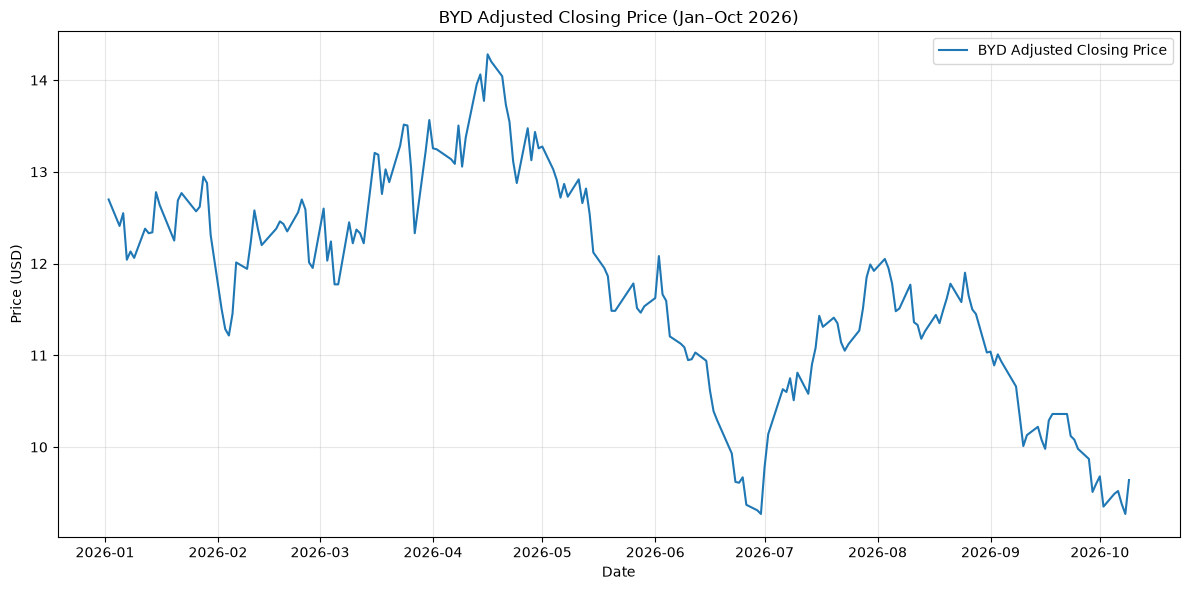

In [7]:
# Plot BYD's adjusted closing price over time
plt.figure(figsize=(12, 6))

plt.plot(
    byd.index,
    byd["Close"],
    label="BYD Adjusted Closing Price"
)

plt.title("BYD Adjusted Closing Price (Jan–Oct 2026)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

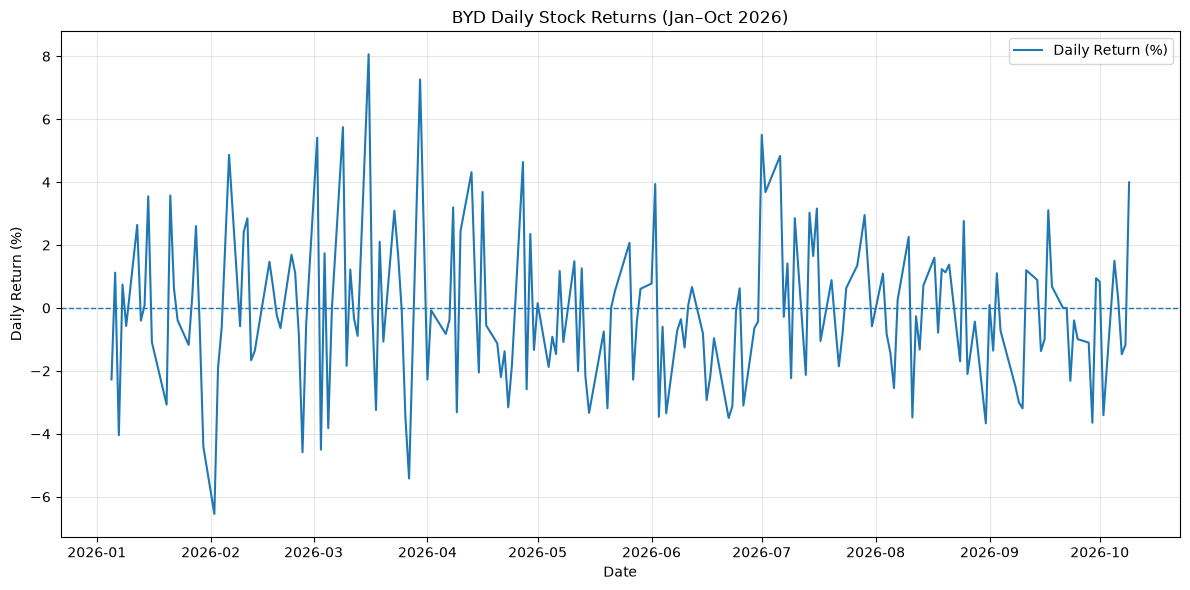

In [8]:
# Plot BYD's daily percentage returns
plt.figure(figsize=(12, 6))

plt.plot(
    byd.index,
    byd["Daily Return"],
    label="Daily Return (%)"
)

plt.axhline(y=0, linestyle="--", linewidth=1)
plt.title("BYD Daily Stock Returns (Jan–Oct 2026)")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Summarize BYD's stock performance
first_close = byd["Close"].iloc[0]
last_close = byd["Close"].iloc[-1]

total_return = (last_close / first_close - 1) * 100
best_day = byd["Daily Return"].idxmax()
worst_day = byd["Daily Return"].idxmin()

print("BYD Stock Performance Summary")
print("-----------------------------")
print(f"First adjusted close: ${first_close:.2f}")
print(f"Last adjusted close: ${last_close:.2f}")
print(f"Total price return: {total_return:.2f}%")
print(f"Best day: {best_day.date()} ({byd.loc[best_day, 'Daily Return']:.2f}%)")
print(f"Worst day: {worst_day.date()} ({byd.loc[worst_day, 'Daily Return']:.2f}%)")

BYD Stock Performance Summary
-----------------------------
First adjusted close: $12.70
Last adjusted close: $9.64
Total price return: -24.09%
Best day: 2026-03-16 (8.06%)
Worst day: 2026-02-02 (-6.55%)


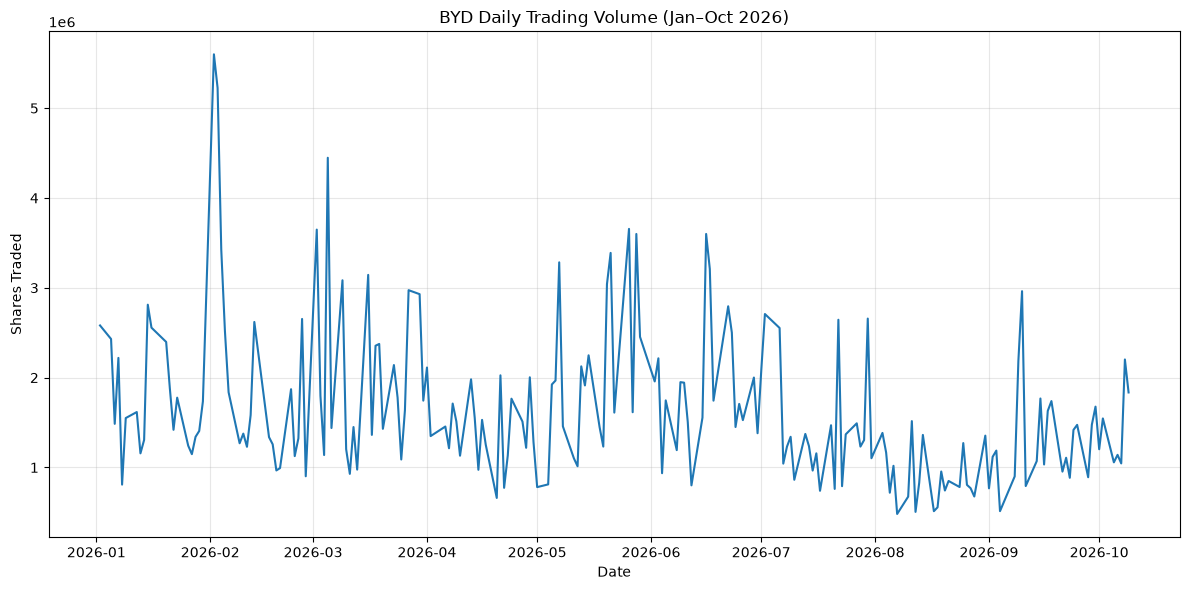

In [10]:
# Plot BYD daily trading volume
plt.figure(figsize=(12, 6))

plt.plot(byd.index, byd["Volume"])

plt.title("BYD Daily Trading Volume (Jan–Oct 2026)")
plt.xlabel("Date")
plt.ylabel("Shares Traded")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Find the day with the highest trading volume
highest_volume_date = byd["Volume"].idxmax()

print("BYD Highest Trading Volume")
print("--------------------------")
print("Date:", highest_volume_date.date())
print("Volume:", f"{byd.loc[highest_volume_date, 'Volume']:,}")
print(
    "Daily Return:",
    f"{byd.loc[highest_volume_date, 'Daily Return']:.2f}%"
)
print(
    "Closing Price:",
    f"${byd.loc[highest_volume_date, 'Close']:.2f}"
)

BYD Highest Trading Volume
--------------------------
Date: 2026-02-02
Volume: 5,599,500
Daily Return: -6.55%
Closing Price: $11.50


In [12]:
# Compare highest-volume day with average trading volume
average_volume = byd["Volume"].mean()
highest_volume = byd["Volume"].max()
volume_multiple = highest_volume / average_volume

print("Trading Volume Comparison")
print("-------------------------")
print(f"Average daily volume: {average_volume:,.0f} shares")
print(f"February 2 volume: {highest_volume:,.0f} shares")
print(f"Compared with average: {volume_multiple:.2f} times")

Trading Volume Comparison
-------------------------
Average daily volume: 1,640,636 shares
February 2 volume: 5,599,500 shares
Compared with average: 3.41 times


### Business Analysis: BYD's February 2, 2026 Stock Decline

On February 2, 2026, BYD's U.S.-listed shares (BYDDY) declined by 6.55%, while trading volume reached 5,599,500 shares, approximately 3.41 times the average daily volume during the analysis period. Reuters reported that BYD's January vehicle sales fell 30.1% compared with the previous year, raising concerns about weakening demand in China and increased competition from other electric-vehicle manufacturers. These developments may have contributed to negative investor sentiment and increased selling activity. The combination of a sharp price decline and unusually high trading volume suggests that the market reacted strongly to the news. However, the relationship does not prove that the news alone caused the stock's movement.